# FBG Accelerometer Data Analysis

This notebook processes and analyses Fiber Bragg Grating (FBG) sensor data recorded during the experiment.

The workflow includes:

1. Converting raw tab-separated FBG files to an `xarray.Dataset`.
2. Saving and loading the data in NetCDF format.
3. Combining the two FBG wavelength measurements.
4. Applying bandpass filtering and detrending.
5. Computing 15-minute and hourly RMS values.
6. Comparing the FBG measurements with data from a conventional seismometer.

The analysis covers the period from 21 to 28 June 2024 and aims to evaluate the seismic response captured by the FBG accelerometer.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import xarray as xr
import datetime
from scipy.signal import detrend, decimate, correlate,correlation_lags
from obspy.signal.filter import bandpass, highpass
from tqdm import tqdm
import os, glob

## Processing FBG data

### Converting FBG data to nc

In [ ]:
# Directory containing the .txt files
directory = '../data/rob_acc/2024*.txt'

# List to hold dataframes
dfs = []
files = glob.glob(directory)
files.sort()

In [ ]:

# Loop through all files in the directory
for filename in files:
    file_path = os.path.join(filename)
    df = pd.read_csv(file_path, delimiter='\t', index_col='Time [sec]', decimal=',',engine='python')  # Adjust delimiter if necessary
    dfs.append(df)

# Concatenate all dataframes
concatenated_df = pd.concat(dfs, ignore_index=False)

In [ ]:
date = files[0].split('/')[-1].split('.')[0]

date = datetime.datetime.strptime(date, '%Y%m%dT%H%M%SZ')

In [ ]:
dtime = concatenated_df.index.to_numpy()
dtime *= 1000
dtime = dtime.astype(int)
dtime -= dtime[0]


In [ ]:
date = np.datetime64(date, "ms") + dtime

In [ ]:
concatenated_df.index = date

In [ ]:
dataset = concatenated_df.to_xarray()

In [ ]:
dataset.to_netcdf(f'../rob_acc/experiment.nc')

## Importing nc

In [4]:
dataset = xr.open_dataset('../data/rob_acc/experiment.nc')

### Working in wavelength shift and merge the 2 FBGs

In [5]:
wav1 = dataset['Wavelength 1[nm]'] - np.mean(dataset['Wavelength 1[nm]'])
wav2 = dataset['Wavelength 2[nm]'] - np.mean(dataset['Wavelength 2[nm]'])

Twav = np.median([wav1, wav2], axis=0)#.resample(index='0.01S').mean()
del wav1, wav2  # Free up memory

### Bandpass and detrend the waveform

In [6]:
wav = bandpass(Twav,1,75,500)
wav = detrend(wav)

In [29]:
time = dataset.index.to_numpy()

### Calculate RMS

In [41]:
def rms(wav, time, min=15, fs=500) :

    nhour = wav.shape[0]/(fs*60*min)
    nhour
    rms = []
    rmstime = []
    for i in range(0,int(nhour)):
        idx0 = fs*i*60*min
        idx1 = fs*i*60*min + fs*60*min
        dwav = wav[idx0:idx1]
        dtime = time[idx0:idx1]
        rmstime.append(dtime[int(len(dtime)/2)])
        rms.append(np.sqrt(np.mean(dwav**2)))
    return np.array(rmstime), np.array(rms)

In [42]:
tim15m, rms15m = rms(wav, time,min=15, fs=500)
tim1h, rms1h =  rms(wav, time, min=60, fs=500)

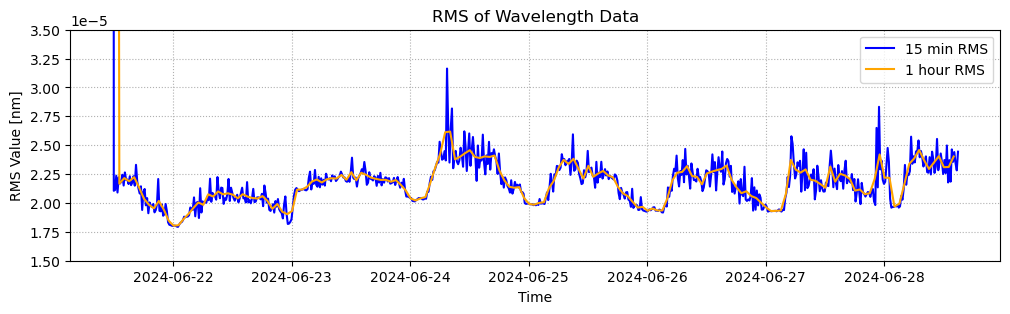

In [44]:
plt.figure(figsize=(12, 3))
plt.plot(tim15m, rms15m, label='15 min RMS', color='blue')
plt.plot(tim1h, rms1h, label='1 hour RMS', color='orange')
plt.xlabel('Time')
plt.ylabel('RMS Value [nm]')
plt.title('RMS of Wavelength Data')
plt.ylim(1.5e-5,3.5e-5)
plt.grid(ls=':')
plt.legend()

### Processing the seismic data from a conventionnal seismometer

In [45]:
from obspy.clients.fdsn import Client
import obspy
client = Client("ORFEUS")

In [46]:
ucc_rms1h = []
time_ucc = []
for i in tqdm(range(8*24)) :
    stttime = np.datetime64('2024-06-21T00:00:00') + np.timedelta64(i,'h')
    endtime = np.datetime64('2024-06-21T00:00:00') + np.timedelta64(i+1,'h')
    time_ucc.append(stttime+np.timedelta64(30,'m'))
    stt = obspy.UTCDateTime(stttime.astype(str))
    stp = obspy.UTCDateTime(endtime.astype(str))
    st = client.get_waveforms('BE', 'UCCA', '--', 'HNZ', stt, stp, attach_response=True)
    st.remove_response(output='ACC')#, pre_filt=(0.001, 0.005, 80, 90), water_level=60)
    st.filter('bandpass', freqmin=1, freqmax=75)
    st.detrend('linear')
    
    ucc_rms1h.append(np.sqrt(np.mean(st[0].data**2)))

100%|██████████| 192/192 [06:36<00:00,  2.07s/it]


### Comparison between the conventional seismometer and the FBG-accelerometer

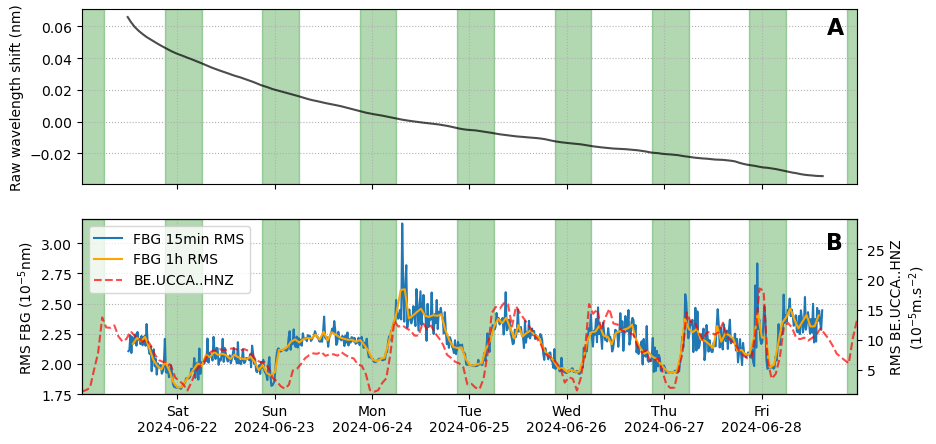

In [49]:
import matplotlib.dates as mdates

fig, ax = plt.subplots(figsize=(10,5), nrows=2, sharex=True)
fbgrms15, = ax[1].plot(tim15m[1:], np.array(rms15m[1:])*1e5, alpha=1, label='FBG 15min RMS')
fbgrms1h, = ax[1].plot(tim1h[1:], np.array(rms1h[1:])*1e5, c='orange', label='FBG 1h RMS')
# remove the first value of rms15m and rms1h to avoid plotting the noise generated by the installation of the FBG
ax[1].set_ylim(1.75, 3.2)

ax[1].grid(ls=':')
#ax.set_xlabel('Time')
ax[1].set_ylabel('RMS FBG (10$^{-5}$nm)')

# Change the date format and include the name of the day
date_format = mdates.DateFormatter('%a\n%Y-%m-%d')
ax[1].xaxis.set_major_formatter(date_format)
#fig.autofmt_xdate()

for i in range(-1,8):
    sttime = np.datetime64('2024-06-21T21:00:00') + np.timedelta64(i,'D')
    endtime = np.datetime64('2024-06-22T06:00:00') + np.timedelta64(i,'D')
    ax[0].axvspan(sttime, endtime, color='g', alpha=0.3)
    ax[1].axvspan(sttime, endtime, color='g', alpha=0.3)
axb = ax[1].twinx()
pltucc, = axb.plot(time_ucc, ucc_rms1h, c='red', alpha=.7,ls='--', label=st[0].id)
axb.set_ylabel('RMS %s\n(10$^{-5}$m.s$^{-2}$)' %st[0].id)
axb.set_ylim(1e-5, 30e-5)
axb.set_yticks(np.arange(5e-5,30e-5,5e-5), np.arange(5,30,5))
ax[1].legend(handles=[fbgrms15,fbgrms1h,pltucc], loc='upper left')
ax[1].set_xlim(time_ucc[0], time_ucc[-1])

da = xr.DataArray(Twav, dims=['index'], coords={'time': dataset.index})
ax[0].plot(da.time.resample(time='1h').mean(), da.resample(time='1h').mean(), label='FBG', c='black', alpha=.7)
#ax[1].plot(da.time.resample(time='1h').mean(), detrend(da.resample(time='1h').mean()), label='FBG', c='black', ls='--', alpha=.7)
ax[0].set_ylabel('Raw wavelength shift (nm)')
ax[0].grid(ls=':')

ax[0].text(np.datetime64('2024-06-28T16'), 0.055, 'A', fontsize=16, fontweight='bold')
axb.text(np.datetime64('2024-06-28T16'), 25e-5, 'B', fontsize=16, fontweight='bold')

plt.savefig('../plots/rms_acc_rob.jpeg', dpi=300, bbox_inches='tight', transparent=True)

### Linear regression between the two RMS

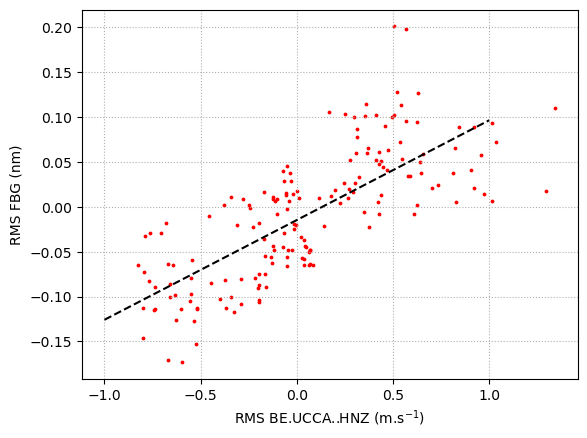

In [52]:
plt.scatter((ucc_rms1h[13:-9]-np.median(ucc_rms1h[13:-9]))/np.median(ucc_rms1h[13:-9]), (rms1h[1:]-np.median(rms1h[1:]))/np.median(rms1h[1:]), c='r',s=3)
plt.xlabel('RMS %s (m.s$^{-1}$)' %st[0].id)
plt.ylabel('RMS FBG (nm)')
m,p = np.polyfit((ucc_rms1h[13:-9]-np.median(ucc_rms1h[13:-9]))/np.median(ucc_rms1h[13:-9]), (rms1h[1:]-np.median(rms1h[1:]))/np.median(rms1h[1:]), 1)
plt.plot(np.arange(-1,2), m*np.arange(-1,2)+p, c='k', ls='--', label='Linear fit')
plt.grid(ls=':')
plt.savefig('../plots/rms_acc_rob_scatter.png', dpi=300, bbox_inches='tight')